# 01 · Prepare village boundaries

**Purpose:** turn the raw SHRUG village polygons into clean, analysis-ready village files and the zipped shapefiles that Earth Engine needs.

| | |
|---|---|
| **Inputs** (`data/raw/`) | `village_modified.gpkg` – SHRUG PC11 village & town polygons · `shrid_pop_area_key.csv` – SHRUG population/area per SHRID |
| **Outputs** (`data/processed/`) | `villages_06.gpkg` + `villages_06_shp.zip` (Haryana pilot) · `villages_india.gpkg` + `villages_india_shp.zip` (all India) |
| **Next step** | Upload both `.zip` files to Earth Engine as assets (see the end of this notebook), then run `02_extract_signals` |
| **Run time** | ~1 min for the pilot, ~10 min for all India (the raw file is ~900 MB) |

**Pipeline position:** **01 Prepare** → 02 Extract → 03 Score & rank → 04 Visualise

In [14]:
import shutil
from pathlib import Path

import geopandas as gpd
import pandas as pd

# ---- Paths (relative, so the notebook runs on any machine that clones the repo) ----
# Works whether the notebook sits in the repo root or in a sub-folder such as notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
PROC.mkdir(parents=True, exist_ok=True)

# ---- Settings ----
PILOT_STATE = "06"            # Census 2011 (PC11) state code: 06 = Haryana, used to test the pipeline
SIMPLIFY_PILOT = 0.0003       # geometry simplification in degrees (~30 m) for the pilot upload
SIMPLIFY_INDIA = 0.0005       # ~50 m for the national upload (keeps the file small enough for Earth Engine)
EQUAL_AREA_CRS = 6933         # equal-area projection used to compute village area in km²

KEEP_COLS = ["shrid2", "pc11_state_id", "pc11_district_id", "pc11_subdistrict_id",
             "town_village_name", "pop_2011", "area_km2", "geometry"]

## Cleaning rules

Every village goes through the same steps (implemented once in `load_and_clean()` below):

1. **Build the SHRUG ID (`shrid2`)** – `"11-" + state + district + sub-district + village` (PC11 codes). This lets us join SHRUG data without a separate key file (~93% of polygons match directly).
2. **Drop placeholder rows** – polygons with village code `000000` or no name.
3. **Drop statutory towns** – PC11 town codes are `800000` and above (e.g. Faridabad, Gurgaon). The task is about *villages*.
4. **Drop villages with no 2011 population** – needed for the minimum-population filter and per-village context.
5. **Repair geometries** and drop empty ones.
6. **Compute area (km²)** in an equal-area projection.

>  **My reasoning for these rules:** 648,878 polygons → 591,717 villages kept. 93% matched to population. Towns have codes 800000+ (e.g. Faridabad 1.4M people). Unmatched polygons are mostly merged or uninhabited units.

In [15]:
def add_shrid(gdf):
    # SHRUG ID = "11-<state>-<district>-<subdistrict>-<village>" (the "11" prefix = Census 2011 vintage)
    gdf["shrid2"] = ("11-" + gdf["pc11_state_id"] + "-" + gdf["pc11_district_id"] + "-"
                     + gdf["pc11_subdistrict_id"] + "-" + gdf["pc11_town_village_id"])
    return gdf


def load_population():
    # 2011 population and Census land area for every SHRID
    pop = pd.read_csv(RAW / "shrid_pop_area_key.csv", dtype={"shrid2": str},
                      usecols=["shrid2", "shrid_pc11_pca_tot_p", "shrid_pc11_land_area"])
    return pop.rename(columns={"shrid_pc11_pca_tot_p": "pop_2011",
                               "shrid_pc11_land_area": "area_km2_census"})


def load_and_clean(where=None):
    # Load village polygons (optionally only a subset via an SQL `where`) and apply the cleaning rules
    gdf = gpd.read_file(RAW / "village_modified.gpkg", where=where)
    n0 = len(gdf)

    gdf = add_shrid(gdf).merge(load_population(), on="shrid2", how="left")
    print(f"Loaded {n0:,} polygons | matched to 2011 population: {gdf['pop_2011'].notna().sum():,}")

    gdf = gdf[(gdf["pc11_town_village_id"] != "000000") & gdf["town_village_name"].notna()]  # rule 2
    gdf = gdf[gdf["pc11_town_village_id"] < "800000"]                                         # rule 3
    gdf = gdf[gdf["pop_2011"].notna()].copy()                                                 # rule 4

    gdf["geometry"] = gdf.geometry.make_valid()                                               # rule 5
    gdf = gdf[~gdf.geometry.is_empty].copy()

    gdf["area_km2"] = gdf.to_crs(epsg=EQUAL_AREA_CRS).area / 1e6                              # rule 6
    print(f"Kept {len(gdf):,} of {n0:,} polygons after cleaning")
    return gdf


def save_for_earth_engine(gdf, name, tolerance, include_state=False):
    # Simplify shapes (smaller upload, area barely changes), save a GeoPackage for later notebooks
    # and a zipped shapefile for the Earth Engine asset upload
    gdf = gdf.copy()
    gdf["geometry"] = gdf.geometry.simplify(tolerance, preserve_topology=True)
    gdf[KEEP_COLS].to_file(PROC / f"{name}.gpkg", driver="GPKG")

    # Shapefiles only allow 10-character column names -> keep just what Earth Engine needs
    cols = ["shrid2", "pop_2011", "geometry"]
    shp = gdf.rename(columns={"pc11_state_id": "state"})
    if include_state:
        cols.insert(1, "state")        # used in notebook 02 to export one task per state
    shp_dir = PROC / f"{name}_shp"
    shp_dir.mkdir(exist_ok=True)
    shp[cols].to_file(shp_dir / f"{name}.shp")
    zip_path = shutil.make_archive(str(shp_dir), "zip", shp_dir)
    print(f"Saved {name}.gpkg and {Path(zip_path).name} ({len(gdf):,} villages)")
    return gdf

## Part A · Pilot state (Haryana)

Before processing ~600,000 villages, the whole pipeline was tested on one mid-sized state (Haryana, ~7,000 villages) to check the data, the Earth Engine extraction and the scoring logic quickly.

In [16]:
pilot = load_and_clean(where=f"pc11_state_id = '{PILOT_STATE}'")
pilot = save_for_earth_engine(pilot, f"villages_{PILOT_STATE}", SIMPLIFY_PILOT)
pilot[["pop_2011", "area_km2"]].describe().round(1)

Loaded 6,998 polygons | matched to 2011 population: 6,761
Kept 6,681 of 6,998 polygons after cleaning
Saved villages_06.gpkg and villages_06_shp.zip (6,681 villages)


,pop_2011,area_km2
count,6681.0,6681.0
mean,2605.9,6.2
std,2813.6,6.9
min,1.0,0.1
25%,992.0,2.2
50%,1823.0,4.0
75%,3280.0,7.8
max,67998.0,147.8


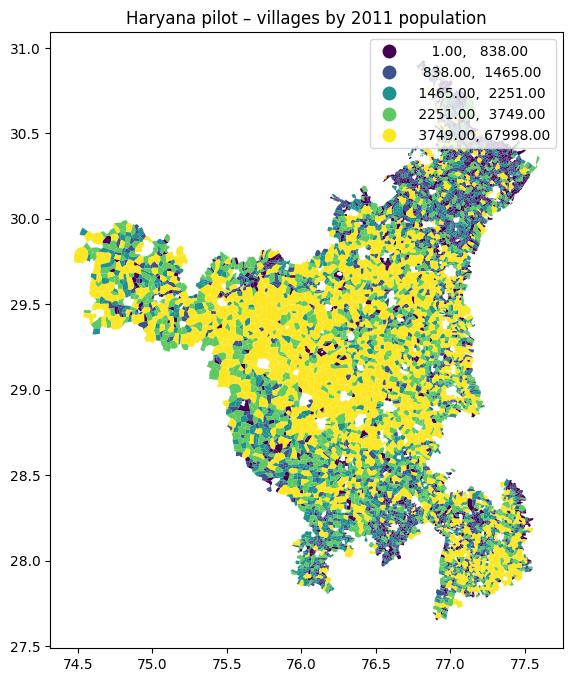

In [17]:
# Visual check: the villages should form the outline of Haryana (colour = 2011 population, quintiles)
ax = pilot.plot(column="pop_2011", scheme="quantiles", k=5, legend=True,
                figsize=(8, 8), edgecolor="none")
ax.set_title("Haryana pilot – villages by 2011 population");

## Part B · All India

Same rules, applied to every state. Reading the full ~900 MB file takes a few minutes.

In [18]:
india = load_and_clean()
india = save_for_earth_engine(india, "villages_india", SIMPLIFY_INDIA, include_state=True)
print("States covered:", india["pc11_state_id"].nunique())

Loaded 648,878 polygons | matched to 2011 population: 595,617
Kept 591,717 of 648,878 polygons after cleaning
Saved villages_india.gpkg and villages_india_shp.zip (591,717 villages)
States covered: 33


## Manual step · Upload to Earth Engine

Upload both zip files from `data/processed/` in the Earth Engine Code Editor (**Assets → NEW → Shape files**):

| File | Asset ID used in notebook 02 |
|---|---|
| `villages_06_shp.zip` | `villages_06_shp` |
| `villages_india_shp.zip` | `villages_india_shp` |

Wait until both uploads show as completed in the **Tasks** tab, then run `02_extract_signals`.